# Setup, Data and Smoke Test
**DS 677 · Florence-2 vs. Specialist Models Under Motion Blur** · Vivek Shah and Victor Figueredo

**Claim:** Florence-2-base-ft's relative performance drop, (clean score − degraded score) ÷ clean score, is smaller than that of single-task models as motion blur increases, tested against BLIP-base for captioning (CIDEr, MS COCO Karpathy test split) and DETR-ResNet-50 for object detection (mAP, MS COCO val2017).

### What this notebook does
Phase 1 prepares everything the experiments need before any blur is added:

| What happens |
|---|
| Install packages and get the team's latest code from GitHub |
| Download the captioning and detection datasets |
| Write the shared settings file `src/config.py` |
| Write the data loaders `src/data.py` |
| Check the data is complete |
| Look at one example image and caption |
| Smoke test: captioning with Florence-2 and BLIP |
| Smoke test: detection with Florence-2 and DETR |

### Files this notebook produces
- `src/config.py`: shared settings (data location, blur levels, seeds, beam size, results format)
- `src/data.py`: functions that load the two datasets

## Step 1 · Install packages and get the team's code
- Installs the packages the project needs. `transformers==4.49.0` matches the version pinned in the repo's `requirements.txt`.
- Clones a fresh copy of the GitHub repo into `/content/repo`, so this notebook always uses the latest code.
- Adds the repo to Python's search path so `from src... import ...` works.

**Result:** the latest commit is shown.

In [1]:
# Install pinned package versions
!pip install -q transformers==4.49.0 timm einops pycocotools==2.0.11

# Refresh the copy of the GitHub repo
!rm -rf /content/repo
!git clone -q https://github.com/NJIT-DS677-Deep-Learning/florence2-vs-specialists-motion-blur.git /content/repo
# Move into the repo folder
%cd /content/repo
# Show the latest commit
!git log -1 --oneline

import sys
# Let Python import modules from the repo's src/ folder
sys.path.insert(0, '/content/repo')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
/content/repo
f842816 (HEAD -> main, origin/main, origin/HEAD) Add Florence-2 inference, dependencies, and test scripts


## Step 2 · Download the datasets
Downloads four files from their official sources into `/content/data`:

| File | Size | Used for |
|---|---|---|
| `val2014.zip` | 6.2 GB | Captioning images (the Karpathy test images come from COCO 2014 val) |
| `val2017.zip` | 0.8 GB | Detection images |
| `annotations_trainval2017.zip` | 0.24 GB | Ground-truth boxes for detection |
| `caption_datasets.zip` | 35 MB | `dataset_coco.json`: which images are in the Karpathy test split, and their human captions |

The zips are unpacked and then deleted to save space. The Flickr files that come with the Karpathy zip are not used.

**Result:** all four downloads completed, and `/content/data` contains `annotations`, `dataset_coco.json`, `val2014` and `val2017`.

In [2]:
# Create the data folder outside the repo, so data is never committed
!mkdir -p /content/data
%cd /content/data

# Captioning images: COCO 2014 val, the source of the Karpathy test images
!wget -q --show-progress http://images.cocodataset.org/zips/val2014.zip
# Detection images: COCO 2017 val
!wget -q --show-progress http://images.cocodataset.org/zips/val2017.zip
# Detection ground truth: box annotations for COCO 2017
!wget -q --show-progress http://images.cocodataset.org/annotations/annotations_trainval2017.zip
# Karpathy split file: lists the 5,000 test images and their human captions
!wget -q --show-progress https://cs.stanford.edu/people/karpathy/deepimagesent/caption_datasets.zip

# Unpack each zip
!unzip -q -o val2014.zip
!unzip -q -o val2017.zip
!unzip -q -o annotations_trainval2017.zip
!unzip -q -o caption_datasets.zip

# Make sure dataset_coco.json sits directly in /content/data
!mv $(find /content/data -name dataset_coco.json | head -1) /content/data/ 2>/dev/null

# Delete Zip Files
!rm -f *.zip

# List what was downloaded
!ls /content/data
%cd /content/repo

/content/data
val2014.zip         100%[===================>]   6.19G  16.4MB/s    in 6m 25s  
val2017.zip         100%[===================>] 777.80M  17.0MB/s    in 48s     
annotations_trainva 100%[===================>] 241.19M  17.1MB/s    in 16s     
caption_datasets.zi 100%[===================>]  35.04M  7.27MB/s    in 6.1s    
annotations	   dataset_flickr30k.json  val2014
dataset_coco.json  dataset_flickr8k.json   val2017
/content/repo


## Step 3 · Shared settings: `src/config.py`
`%%writefile` saves this cell as a file instead of running it. The file keeps every shared setting in one place:

- **`DATA_DIR`**: where the data lives. It defaults to `/content/data` in Colab and can be pointed elsewhere on Wulver with an environment variable, without changing any code.
- **`BLUR_SETTINGS`**: the robustness-probe settings, one entry per blur type:
  - **`linear`**: straight-line motion blur, as if the camera moves in one direction.
  - **`shake`**: curved, random-path motion blur, as if a hand shakes the phone.

  Each type uses the same severity scale (blur extent in pixels: 0, 15, 30, 45), so results can be compared across types. Level 0 is the clean image, run once and shared by all types.
- **`SEEDS`**: each seed sets a different blur direction or shake path, so results don't depend on one particular blur.
- **`NUM_BEAMS`**: the beam-search width, shared by Florence-2 and BLIP so the captioning comparison is fair.
- **`RESULTS_COLUMNS`**: the agreed layout of the results table both teammates write to. The `blur_type` column records which kind of blur produced each row.

**Result:** `Writing /content/repo/src/config.py`

In [13]:
%%writefile /content/repo/src/config.py
# Shared project settings.
import os

# Folder with val2014/, val2017/, annotations/, dataset_coco.json
DATA_DIR = os.environ.get("DATA_DIR", "/content/data")
# Folder where result files are saved
RESULTS_DIR = "experiments/results"

# Blur types and their severity levels (blur extent in pixels; 0 = clean, run once and shared by all types)
BLUR_SETTINGS = {
    # Straight-line motion blur (camera moving in one direction)
    "linear": [0, 15, 30, 45],
    # Curved, random-path motion blur (hand shake)
    "shake":  [0, 15, 30, 45]
}

# Each seed sets a different blur direction or shake path
SEEDS = [0, 1, 2]
# Beam search width, same for Florence-2 and BLIP
NUM_BEAMS = 3

# One row per run in experiments/results/results.csv
RESULTS_COLUMNS = ["model", "task", "blur_type", "blur_px", "seed", "metric", "score", "n_images", "date", "notes"]

Overwriting /content/repo/src/config.py


## Step 4 · Data loaders: `src/data.py`
Saves the data-loading code as `src/data.py`, so every notebook and Wulver job loads data the same way:
```python
from src.data import load_karpathy_test, load_val2017, open_image
```

| Function | Returns |
|---|---|
| `open_image(path)` | The image as RGB. Some COCO images are grayscale, and the models expect RGB. |
| `load_karpathy_test()` | A list of the 5,000 Karpathy test images: `image_id`, `path` and `references` (the human captions) |
| `load_val2017()` | A list of the 5,000 val2017 images (`image_id`, `path`), plus the `coco` object holding the ground-truth boxes, which is needed later to calculate mAP |

**Result:** `Writing /content/repo/src/data.py`

In [14]:
%%writefile /content/repo/src/data.py
# Load the two evaluation datasets.
# Captioning: MS COCO Karpathy test split (5,000 images, 5+ human captions each)
# Detection:  MS COCO val2017 (5,000 images with ground-truth boxes)

import json
import os

from PIL import Image
from pycocotools.coco import COCO

from src.config import DATA_DIR


def open_image(path):
  # Open an image as RGB. Some COCO images are grayscale, and the models expect RGB.
  return Image.open(path).convert("RGB")


def load_karpathy_test(data_dir=DATA_DIR):
  # Return a list of dicts, one per test image: image_id, path, references.
  #Read the Karpathy split file, which lists every COCO image and its split
  with open(os.path.join(data_dir, "dataset_coco.json")) as f:
    images = json.load(f)["images"]

  items = []
  for im in images:
    # Keep only the 5K images in the test split
    if im["split"] == "test":
      items.append({
        # COCO's numeric image ID
        "image_id": im["cocoid"],
        # Full path to the image file
        "path": os.path.join(data_dir, im["filepath"], im["filename"]),
        # All human reference captions
        "references": [s["raw"] for s in im["sentences"]]
      })
  return items


def load_val2017(data_dir=DATA_DIR):
  # Return (items, coco)

  # items: a list of dicts, one per image: image_id, path
  # coco:  the pycocotools object holding the ground-truth boxes (used later for mAP)

  # Load the official val2017 box annotations
  coco = COCO(os.path.join(data_dir, "annotations", "instances_val2017.json"))

  items = []
  # Go through images in ID order so every run uses the same order
  for image_id in sorted(coco.getImgIds()):
    file_name = coco.imgs[image_id]["file_name"]
    items.append({
      # COCO's numeric image ID
      "image_id": image_id,
      # Full path to the image file
      "path": os.path.join(data_dir, "val2017", file_name)
    })
  return items, coco

Overwriting /content/repo/src/data.py


## Step 5 · Check the data is complete
Loads both datasets with the new functions and check the counts against what the project expects.

**Result: every check passed.**

| Check | Expected | Got |
|---|---|---|
| Karpathy test images | 5,000 | 5,000 |
| val2017 images | 5,000 | 5,000 |
| Object categories | 80 | 80 |
| Fewest human captions on one image | 5 | 5 |
| Missing image files | 0 | 0 |

In [5]:
import os
from src.data import load_karpathy_test, load_val2017, open_image

# Load both datasets with the new loader functions
captions = load_karpathy_test()
detection, coco = load_val2017()

# Compare each count with the expected value
print("Karpathy test images:", len(captions), "(expect 5000)")
print("val2017 images:", len(detection), "(expect 5000)")
print("Object categories:", len(coco.getCatIds()), "(expect 80)")
print("Fewest captions on one image:", min(len(x["references"]) for x in captions), "(expect 5)")

# Confirm every listed image file actually exists on disk
missing = [x["path"] for x in captions + detection if not os.path.exists(x["path"])]
print("Missing image files:", len(missing), "(expect 0)")

loading annotations into memory...
Done (t=1.09s)
creating index...
index created!
Karpathy test images: 5000 (expect 5000)
val2017 images: 5000 (expect 5000)
Object categories: 80 (expect 80)
Fewest captions on one image: 5 (expect 5)
Missing image files: 0 (expect 0)


## Step 6 · Look at one example
Displays the first Karpathy test image with its first human caption, as a quick visual check that each image is paired with the right captions.

**Result:** the caption matches what is in the picture.

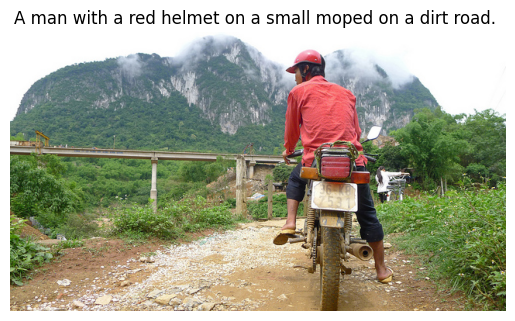

In [6]:
import matplotlib.pyplot as plt

# Take the first Karpathy test image
x = captions[0]
# Show the image with its first human caption as the title
plt.imshow(open_image(x["path"]))
plt.title(x["references"][0])
plt.axis("off")
plt.show()

## Step 7 · Smoke test: captioning
Loads all three models and runs both captioning models on 5 test images, to confirm the models, the data and the team's code all work together before any full-size run.

- **Florence-2** uses `load_florence()` and `generate_caption()` from `src/florence_inference.py` (prompt `<CAPTION>`).
- **BLIP-base** (the captioning baseline) uses 3 beams, matching Florence-2.
- **DETR-ResNet-50** (the detection baseline) is loaded here and used in Step 8. Its warning about unused `num_batches_tracked` weights is expected and harmless.

**Result:** all three models loaded and both captioning models produced captions for every image.

| Image | Florence-2 | BLIP | Human reference |
|---|---|---|---|
| 391895 | A man riding a dirt bike down a dirt road. | a man riding a motorcycle down a dirt road | A man with a red helmet on a small moped on a dirt road. |
| 060623 | A young girl sitting at a table with a bowl of ice cream. | a woman sitting at a table with a lit candle in her mouth | A young girl inhales with the intent of blowing out a candle. |
| 483108 | A man riding a bike down a street next to a train. | the train is red and white | A man on a bicycle riding next to a train |
| 384213 | A kitchen with a sink and two windows. | a kitchen with a sink and a window | A kitchen is shown with a variety of items on the counters. |
| 386164 | Many wooden spoons and forks on a table. | wooden spoons on a table | A wooden ball on top of a wooden stick. |

**Early observations (5 images only, no conclusions yet):**
- Florence-2's captions were usually closer to the human ones. On image 483108, BLIP described only the train and missed the cyclist, the kind of omission that matters most for a visually impaired user.
- Both models made errors on clean images: Florence-2 saw "ice cream" where there is a candle, and BLIP put the candle "in her mouth". Errors like these are the starting point for the failure-case analysis once blur is added.

In [9]:
import torch
from transformers import BlipProcessor, BlipForConditionalGeneration, DetrImageProcessor, DetrForObjectDetection
from src.florence_inference import load_florence, generate_caption, detect_objects

# Use the GPU if one is available
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", device)

# Load Florence-2
florence, florence_proc, _ = load_florence(device)

# Load BLIP-base, the captioning baseline, and its image processor
blip_proc = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
blip = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base").to(device)

# Load DETR-ResNet-50, the detection baseline, and its image processor
detr_proc = DetrImageProcessor.from_pretrained("facebook/detr-resnet-50")
detr = DetrForObjectDetection.from_pretrained("facebook/detr-resnet-50").to(device)

# Caption the first 5 Karpathy test images with both models
for x in captions[:5]:
  img = open_image(x["path"])

  # Florence-2 caption (prompt <CAPTION>)
  florence_caption = generate_caption(florence, florence_proc, img, device)

  # BLIP caption with the same beam width as Florence-2
  inputs = blip_proc(images=img, return_tensors="pt").to(device)
  output = blip.generate(**inputs, num_beams=3, max_new_tokens=30)
  blip_caption = blip_proc.decode(output[0], skip_special_tokens=True)

  # Print both model captions next to a human reference caption
  print(os.path.basename(x["path"]))
  print("Florence-2:", florence_caption)
  print("BLIP:", blip_caption)
  print("Human:", x["references"][0])

Running on: cpu


Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


COCO_val2014_000000391895.jpg
Florence-2: A man riding a dirt bike down a dirt road.
BLIP: a man riding a motorcycle down a dirt road
Human: A man with a red helmet on a small moped on a dirt road. 
COCO_val2014_000000060623.jpg
Florence-2: A young girl sitting at a table with a bowl of ice cream.
BLIP: a woman sitting at a table with a lit candle in her mouth
Human: A young girl inhales with the intent of blowing out a candle. 
COCO_val2014_000000483108.jpg
Florence-2: A man riding a bike down a street next to a train.
BLIP: the train is red and white
Human: A man on a bicycle riding next to a train
COCO_val2014_000000384213.jpg
Florence-2: A kitchen with a sink and two windows.
BLIP: a kitchen with a sink and a window
Human: A kitchen is shown with a variety of items on the counters.
COCO_val2014_000000386164.jpg
Florence-2: Many wooden spoons and forks on a table.
BLIP: wooden spoons on a table
Human: A wooden ball on top of a wooden stick.


## Step 8 · Smoke test: detection
Runs Florence-2 (`detect_objects()`, prompt `<OD>`) and DETR on 3 val2017 images, and compares the object types each model finds with the ground truth. DETR keeps detections with at least 50% confidence, while Florence-2 returns boxes without confidence scores.

**Result:** both models found most of the true objects:

| Image | Florence-2 | DETR | Notes |
|---|---|---|---|
| 000000000139 | 9 object types | 10 object types | Florence-2 missed *book* and *microwave* and added *wine glass*; DETR missed *book* and added *bottle* |
| 000000000285 | bear | bear | Both exactly match the truth |
| 000000000632 | Exact match | Added *bottle* and *vase* | |

**Useful finding:** Florence-2's `<OD>` labels already use COCO category names (e.g. *dining table*, *potted plant*), which should make the label mapping simpler than expected.

In [8]:
# Run both detectors on the first 3 val2017 images
for x in detection[:3]:
  img = open_image(x["path"])

  # Florence-2 detections (prompt <OD>): boxes and labels, no confidence scores
  florence_result = detect_objects(florence, florence_proc, img, device)

  # DETR detections
  inputs = detr_proc(images=img, return_tensors="pt").to(device)
  with torch.no_grad():
    output = detr(**inputs)
  # Keep detections with at least 50% confidence and convert boxes back to the original image size
  detr_result = detr_proc.post_process_object_detection(output, threshold=0.5, target_sizes=[img.size[::-1]])[0]
  # Turn DETR's class numbers into names
  detr_labels = [detr.config.id2label[i.item()] for i in detr_result["labels"]]

  # Ground-truth object names for this image, from the COCO annotations
  true_labels = [coco.cats[a["category_id"]]["name"] for a in coco.loadAnns(coco.getAnnIds(imgIds=x["image_id"]))]

  # Print each list of object types for a side-by-side comparison
  print(os.path.basename(x["path"]))
  print("Florence-2:", sorted(set(florence_result["labels"])))
  print("DETR:", sorted(set(detr_labels)))
  print("Truth:", sorted(set(true_labels)))

000000000139.jpg
Florence-2: ['chair', 'clock', 'dining table', 'person', 'potted plant', 'refrigerator', 'tv', 'vase', 'wine glass']
DETR: ['bottle', 'chair', 'clock', 'dining table', 'microwave', 'person', 'potted plant', 'refrigerator', 'tv', 'vase']
Truth: ['book', 'chair', 'clock', 'dining table', 'microwave', 'person', 'potted plant', 'refrigerator', 'tv', 'vase']
000000000285.jpg
Florence-2: ['bear']
DETR: ['bear']
Truth: ['bear']
000000000632.jpg
Florence-2: ['bed', 'book', 'chair', 'potted plant']
DETR: ['bed', 'book', 'bottle', 'chair', 'potted plant', 'vase']
Truth: ['bed', 'book', 'chair', 'potted plant']


## Summary
- **Data:** the Karpathy test split (5,000 images) and COCO val2017 (5,000 images, 80 categories) are downloaded and complete, with no missing files.
- **Loaders:** `src/data.py` loads both datasets and always returns RGB images.
- **Shared settings:** `src/config.py` holds the data location, blur types and levels, seeds, beam size and results format.
- **Smoke test:** Florence-2, BLIP and DETR all load and run on the project's data, using Victor's Florence-2 code. Both the captioning test (5 images) and the detection test (3 images) produced sensible output.